# CU03 — Estimar el precio de un inmueble (aprendizaje supervisado)

**Objetivo:** que el agente obtenga un precio sugerido al publicar un inmueble, a partir de ciudad, zona, tipo, superficie y ambientes.

**Modelo:** `RandomForestRegressor` (bosque de 200 árboles de decisión). Se eligió porque:
- maneja bien relaciones no lineales (el precio por m² cambia mucho según la zona),
- no necesita escalar las variables,
- da la **importancia de cada variable** y un **rango** (la dispersión entre árboles).

**Datos:** el sistema todavía no tiene suficientes ventas reales, así que se generan **3.000 inmuebles sintéticos** con una regla de mercado explícita (ver `ml/data.py`):

> precio = m² × USD/m²(zona) × factor(tipo) × factor(entrega) × (1 + 1,5 % por comodidad) + 3.000·dormitorios + 2.500·baños + 4.000·parqueos, con un ruido aleatorio de ±10 %.

Los USD/m² por zona son referencias aproximadas del mercado boliviano; antes de producción conviene calibrarlos con 30–50 avisos reales.

In [1]:
%matplotlib inline
import os, sys, warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count() or 1))
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
plt.rcParams['figure.dpi'] = 100

## 1. Datos

In [2]:
from ml.data import generate_properties, ZONE_PRICE_M2
df = generate_properties(n=3000, seed=42)
print(df.shape)
df.head(8)

(3000, 10)


,ciudad,zona,tipo,entrega,superficie_m2,dormitorios,banos,parqueos,comodidades,precio_usd
0,El Alto,Centro,OFICINA,EN_CONSTRUCCION,218.00,0,1,1,3,"103,300.00"
1,Santa Cruz,Sur,DEPARTAMENTO,ENTREGA_INMEDIATA,207.00,5,5,2,4,"196,200.00"
2,Santa Cruz,Plan 3000,CASA,EN_CONSTRUCCION,363.00,7,6,3,7,"201,900.00"
3,La Paz,Sopocachi,DEPARTAMENTO,ENTREGA_INMEDIATA,163.00,5,4,1,0,"256,200.00"
4,Santa Cruz,Centro,CASA,EN_CONSTRUCCION,172.00,4,4,2,1,"180,300.00"
5,La Paz,Villa Fátima,CASA,ENTREGA_INMEDIATA,140.00,4,3,1,2,"104,500.00"
6,El Alto,Centro,CASA,ENTREGA_INMEDIATA,140.00,4,3,2,4,"84,700.00"
7,Cochabamba,Centro,CASA,ENTREGA_INMEDIATA,199.00,4,3,2,4,"171,300.00"


In [3]:
df.describe()[['superficie_m2', 'dormitorios', 'banos', 'parqueos', 'precio_usd']]

,superficie_m2,dormitorios,banos,parqueos,precio_usd
count,"3,000.00","3,000.00","3,000.00","3,000.00","3,000.00"
mean,265.82,2.71,2.57,1.29,"213,162.50"
std,270.35,2.44,1.74,1.07,"137,498.06"
min,27.00,0.00,0.00,0.00,"24,700.00"
25%,117.00,0.00,1.00,0.00,"111,700.00"
50%,187.00,3.00,2.00,1.00,"183,700.00"
75%,295.00,5.00,4.00,2.00,"276,350.00"
max,"1,499.00",7.00,6.00,4.00,"850,700.00"


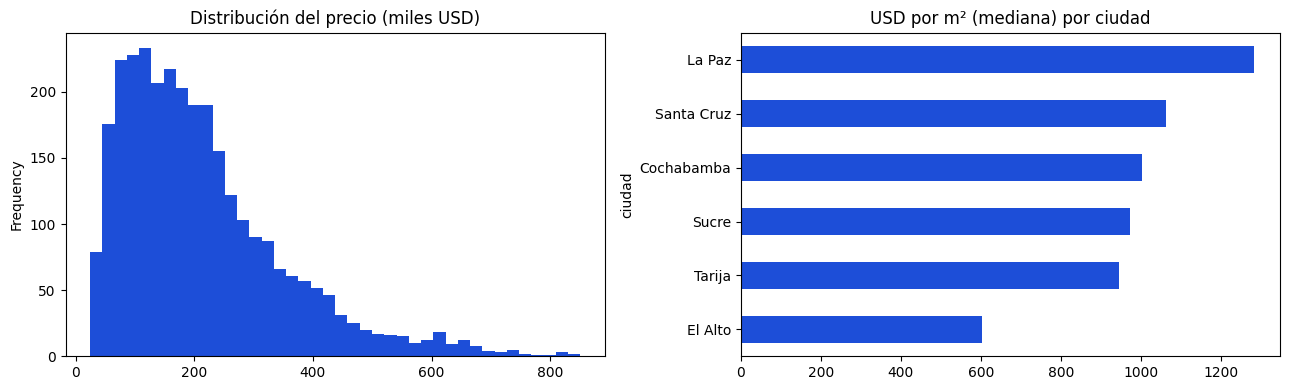

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df['precio_usd'].div(1000).plot.hist(bins=40, ax=axes[0], color='#1d4ed8', title='Distribución del precio (miles USD)')
(df.assign(usd_m2=df.precio_usd / df.superficie_m2)
   .groupby('ciudad')['usd_m2'].median().sort_values()
   .plot.barh(ax=axes[1], color='#1d4ed8', title='USD por m² (mediana) por ciudad'))
plt.tight_layout(); plt.show()

## 2. Preparación y entrenamiento

- Variables categóricas (`ciudad`, `ciudad_zona`, `tipo`, `entrega`) → **one-hot**. Se usa `ciudad_zona` porque "Centro" de La Paz no vale lo mismo que "Centro" de Sucre.
- Variables numéricas (superficie, dormitorios, baños, parqueos, comodidades) → sin transformar.
- División **80 % entrenamiento / 20 % prueba**; el modelo nunca ve los datos de prueba al entrenar.

In [5]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from ml.train import add_price_features, PRICE_CAT, PRICE_NUM

data = add_price_features(df)
X, y = data[PRICE_CAT + PRICE_NUM], data['precio_usd']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = Pipeline([
    ('prep', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), PRICE_CAT), ('num', 'passthrough', PRICE_NUM)])),
    ('rf', RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1)),
])
model.fit(X_train, y_train)
print('Entrenado con', len(X_train), 'inmuebles; prueba con', len(X_test))

Entrenado con 2400 inmuebles; prueba con 600


## 3. Evaluación

In [6]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error
pred = model.predict(X_test)
cv = cross_val_score(model, X, y, cv=5, scoring='r2', n_jobs=-1)
print(f'R² (prueba):              {r2_score(y_test, pred):.3f}')
print(f'Error absoluto medio:     {mean_absolute_error(y_test, pred):,.0f} USD')
print(f'Error porcentual medio:   {mean_absolute_percentage_error(y_test, pred):.1%}')
print(f'R² validación cruzada (5): {cv.round(3)}  → promedio {cv.mean():.3f}')

R² (prueba):              0.890
Error absoluto medio:     30,370 USD
Error porcentual medio:   14.5%
R² validación cruzada (5): [0.908 0.912 0.915 0.922 0.91 ]  → promedio 0.913


**Lectura:** un R² cercano a 0,9 significa que el modelo explica alrededor del 90 % de la variación de precios. El error porcentual (~15 %) está cerca del ruido de ±10 % que se le puso a los datos: el modelo aprendió la regla sin memorizar el ruido. La validación cruzada da valores parecidos en los 5 cortes, así que el resultado no depende de una división con suerte.

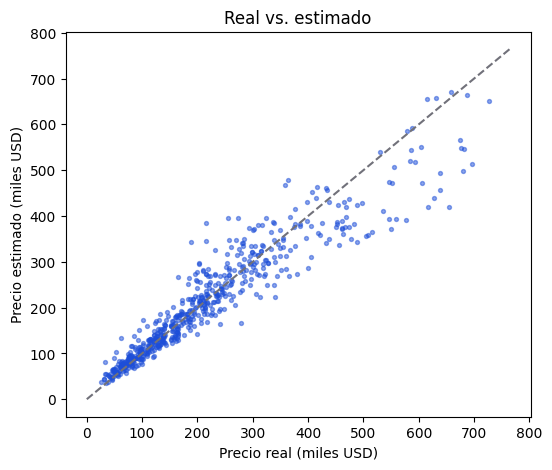

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test / 1000, pred / 1000, s=8, alpha=0.5, color='#1d4ed8')
lim = [0, max(y_test.max(), pred.max()) / 1000 * 1.05]
ax.plot(lim, lim, '--', color='#71717a'); ax.set(xlabel='Precio real (miles USD)', ylabel='Precio estimado (miles USD)', title='Real vs. estimado')
plt.show()

## 4. ¿Qué variables pesan más?

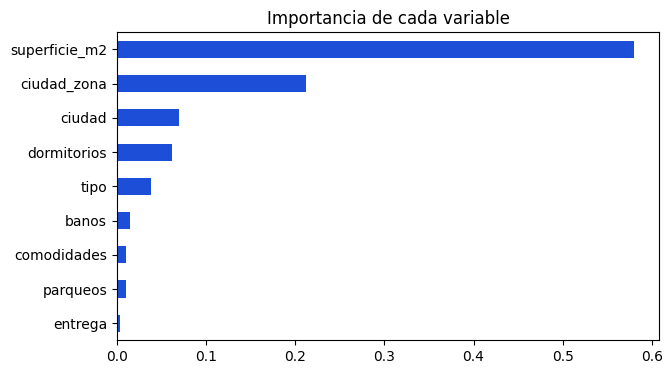

In [8]:
names = model.named_steps['prep'].get_feature_names_out()
imp = {}
for name, value in zip(names, model.named_steps['rf'].feature_importances_):
    feature = name.split('__', 1)[1]
    base = next((c for c in sorted(PRICE_CAT, key=len, reverse=True) if feature.startswith(c + '_')), feature)
    imp[base] = imp.get(base, 0) + value
pd.Series(imp).sort_values().plot.barh(color='#1d4ed8', figsize=(7, 4), title='Importancia de cada variable')
plt.show()

La **superficie** y la **zona** explican la mayor parte del precio, como en el mercado real; dormitorios y tipo ajustan, y el resto (parqueos, comodidades, entrega) aporta poco.

## 5. Ejemplos (lo mismo que hace el botón «Estimar precio»)

In [9]:
ejemplos = pd.DataFrame([
    {'ciudad': 'Santa Cruz', 'zona': 'Equipetrol', 'tipo': 'DEPARTAMENTO', 'entrega': 'ENTREGA_INMEDIATA', 'superficie_m2': 96, 'dormitorios': 2, 'banos': 2, 'parqueos': 1, 'comodidades': 4},
    {'ciudad': 'La Paz', 'zona': 'Calacoto', 'tipo': 'DEPARTAMENTO', 'entrega': 'ENTREGA_INMEDIATA', 'superficie_m2': 96, 'dormitorios': 2, 'banos': 2, 'parqueos': 1, 'comodidades': 4},
    {'ciudad': 'Santa Cruz', 'zona': 'Plan 3000', 'tipo': 'CASA', 'entrega': 'ENTREGA_INMEDIATA', 'superficie_m2': 150, 'dormitorios': 3, 'banos': 2, 'parqueos': 1, 'comodidades': 1},
    {'ciudad': 'Cochabamba', 'zona': 'Queru Queru', 'tipo': 'TERRENO', 'entrega': 'ENTREGA_INMEDIATA', 'superficie_m2': 400, 'dormitorios': 0, 'banos': 0, 'parqueos': 0, 'comodidades': 0},
])
ejemplos['precio_estimado_usd'] = model.predict(add_price_features(ejemplos)[PRICE_CAT + PRICE_NUM]).round(-2)
ejemplos

,ciudad,zona,tipo,entrega,superficie_m2,dormitorios,banos,parqueos,comodidades,precio_estimado_usd
0,Santa Cruz,Equipetrol,DEPARTAMENTO,ENTREGA_INMEDIATA,96,2,2,1,4,"148,100.00"
1,La Paz,Calacoto,DEPARTAMENTO,ENTREGA_INMEDIATA,96,2,2,1,4,"175,200.00"
2,Santa Cruz,Plan 3000,CASA,ENTREGA_INMEDIATA,150,3,2,1,1,"98,100.00"
3,Cochabamba,Queru Queru,TERRENO,ENTREGA_INMEDIATA,400,0,0,0,0,"123,300.00"


## Conclusión

- El random forest estima precios con **R² ≈ 0,9** y un error medio de ~15 %, suficiente para sugerir un precio inicial que el agente ajusta.
- El servicio `ms-ml-python` usa este mismo modelo en `POST /api/v1/ml/predict-price` y devuelve también un **rango** (percentiles 10–90 de los 200 árboles).
- **Límite honesto:** la calidad depende de que los USD/m² por zona reflejen el mercado; con avisos reales se recalibra la tabla y se reentrena con `python -m ml.train`.